In [1]:
import pandas as pd

# Replace the path with your file path
file_path = r'/Users/sainikhil/Downloads/thesis /folder1/healthcare_iot_target_dataset.csv'

# Load the CSV
df = pd.read_csv(file_path)

# Display the column names
print("Columns in the CSV file:")
print(df.columns.tolist())


Columns in the CSV file:
['Patient_ID', 'Timestamp', 'Sensor_ID', 'Sensor_Type', 'Temperature (°C)', 'Systolic_BP (mmHg)', 'Diastolic_BP (mmHg)', 'Heart_Rate (bpm)', 'Device_Battery_Level (%)', 'Target_Blood_Pressure', 'Target_Heart_Rate', 'Target_Health_Status', 'Battery_Level (%)']


In [2]:
import pandas as pd

# Load the CSV
file_path = r'/Users/sainikhil/Downloads/thesis /folder1/healthcare_iot_target_dataset.csv'
df = pd.read_csv(file_path)

# Loop through each column and get unique values and their counts
for column in df.columns:
    print(f"\nColumn: {column}")
    unique_counts = df[column].value_counts(dropna=False)  # dropna=False to include NaNs
    print(unique_counts)



Column: Patient_ID
Patient_ID
8392    2
8270    1
2663    1
4242    1
5636    1
       ..
1878    1
5887    1
5859    1
7331    1
2734    1
Name: count, Length: 199, dtype: int64

Column: Timestamp
Timestamp
2024-01-01 00:00:00    1
2024-01-06 17:00:00    1
2024-01-06 07:00:00    1
2024-01-06 08:00:00    1
2024-01-06 09:00:00    1
                      ..
2024-01-03 21:00:00    1
2024-01-03 22:00:00    1
2024-01-03 23:00:00    1
2024-01-04 00:00:00    1
2024-01-09 07:00:00    1
Name: count, Length: 200, dtype: int64

Column: Sensor_ID
Sensor_ID
4    61
1    50
2    46
3    43
Name: count, dtype: int64

Column: Sensor_Type
Sensor_Type
Battery           56
Blood Pressure    53
Temperature       50
Heart Rate        41
Name: count, dtype: int64

Column: Temperature (°C)
Temperature (°C)
37.300000    26
36.600000    23
37.400000    21
36.900000    21
37.040556    20
37.100000    19
37.500000    15
36.800000    14
37.000000    14
37.200000    11
36.500000     8
36.700000     8
Name: count,

In [3]:
import pandas as pd

# Load the CSV
file_path = r'/Users/sainikhil/Downloads/thesis /folder1/healthcare_iot_target_dataset.csv'
df = pd.read_csv(file_path)

# Display the column names
print("Columns in the CSV file:")
print(df.columns.tolist())

# Check for missing values in each column
print("\nMissing values in each column:")
missing_values = df.isnull().sum()
print(missing_values)

# Quick overview of the dataset
print("\nBasic statistics of numerical columns:")
print(df.describe())

print("\nSample rows from the dataset:")
print(df.head())


Columns in the CSV file:
['Patient_ID', 'Timestamp', 'Sensor_ID', 'Sensor_Type', 'Temperature (°C)', 'Systolic_BP (mmHg)', 'Diastolic_BP (mmHg)', 'Heart_Rate (bpm)', 'Device_Battery_Level (%)', 'Target_Blood_Pressure', 'Target_Heart_Rate', 'Target_Health_Status', 'Battery_Level (%)']

Missing values in each column:
Patient_ID                  0
Timestamp                   0
Sensor_ID                   0
Sensor_Type                 0
Temperature (°C)            0
Systolic_BP (mmHg)          0
Diastolic_BP (mmHg)         0
Heart_Rate (bpm)            0
Device_Battery_Level (%)    0
Target_Blood_Pressure       0
Target_Heart_Rate           0
Target_Health_Status        0
Battery_Level (%)           0
dtype: int64

Basic statistics of numerical columns:
        Patient_ID   Sensor_ID  Temperature (°C)  Systolic_BP (mmHg)  \
count   200.000000  200.000000        200.000000          200.000000   
mean   5720.335000    2.575000         37.040556          125.800000   
std    2588.799649    1.

In [4]:
# Convert Timestamp to datetime
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

# Merge battery columns
df['Battery_Level'] = df['Battery_Level (%)'].combine_first(df['Device_Battery_Level (%)'])

# Encode Target_Health_Status
df['Target_Health_Status'] = df['Target_Health_Status'].map({'Healthy': 0, 'Unhealthy': 1})

# Drop old battery columns
df.drop(['Battery_Level (%)', 'Device_Battery_Level (%)'], axis=1, inplace=True)

# Quick check
print(df.head())
print("\nColumns after cleaning:")
print(df.columns.tolist())


   Patient_ID           Timestamp  Sensor_ID  Sensor_Type  Temperature (°C)  \
0        8270 2024-01-01 00:00:00          4  Temperature              36.8   
1        1860 2024-01-01 01:00:00          1      Battery              37.3   
2        6390 2024-01-01 02:00:00          1  Temperature              36.5   
3        6191 2024-01-01 03:00:00          4      Battery              37.3   
4        6734 2024-01-01 04:00:00          4  Temperature              36.8   

   Systolic_BP (mmHg)  Diastolic_BP (mmHg)  Heart_Rate (bpm)  \
0               150.0                 95.0              84.0   
1               150.0                 95.0              77.0   
2               140.0                 85.0              99.0   
3               120.0                 80.0              67.0   
4                90.0                 60.0              98.0   

   Target_Blood_Pressure  Target_Heart_Rate  Target_Health_Status  \
0                  140.0               90.0                     1   
1 

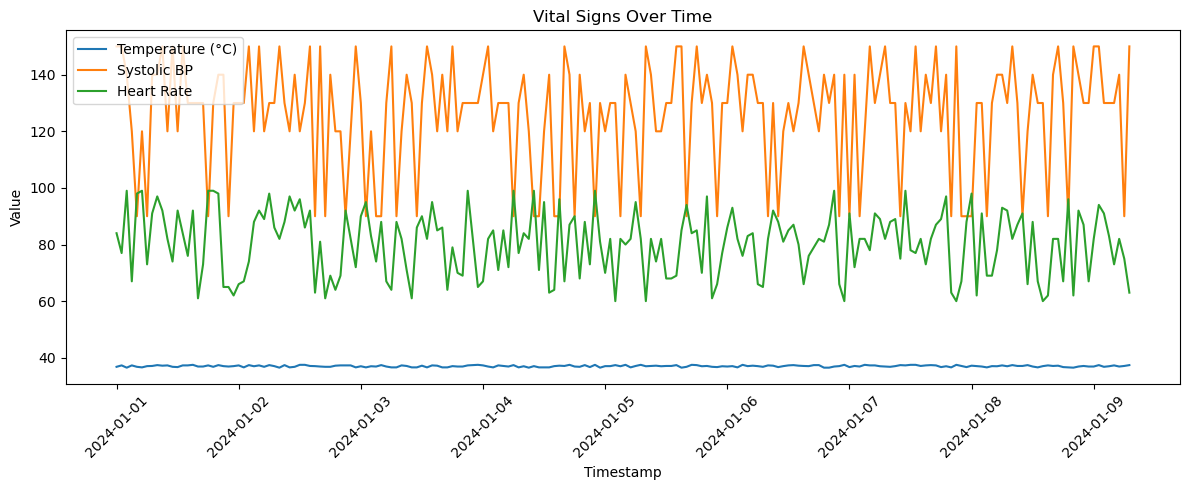

In [5]:
import matplotlib.pyplot as plt

df['Timestamp'] = pd.to_datetime(df['Timestamp'])

plt.figure(figsize=(12, 5))
plt.plot(df['Timestamp'], df['Temperature (°C)'], label='Temperature (°C)')
plt.plot(df['Timestamp'], df['Systolic_BP (mmHg)'], label='Systolic BP')
plt.plot(df['Timestamp'], df['Heart_Rate (bpm)'], label='Heart Rate')
plt.legend()
plt.xlabel("Timestamp")
plt.ylabel("Value")
plt.title("Vital Signs Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


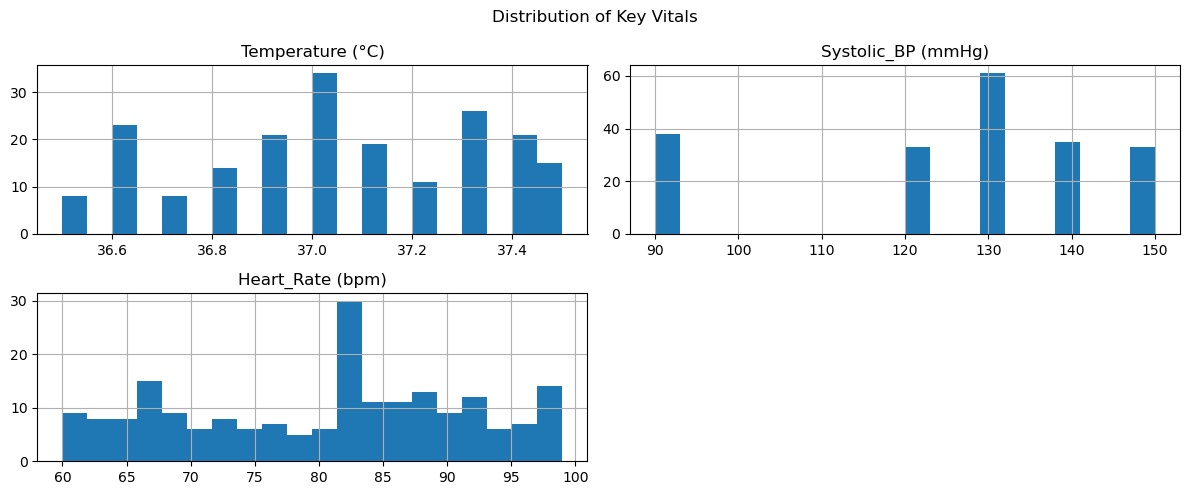

In [6]:
df[['Temperature (°C)', 'Systolic_BP (mmHg)', 'Heart_Rate (bpm)']].hist(bins=20, figsize=(12, 5))
plt.suptitle("Distribution of Key Vitals")
plt.tight_layout()
plt.show()


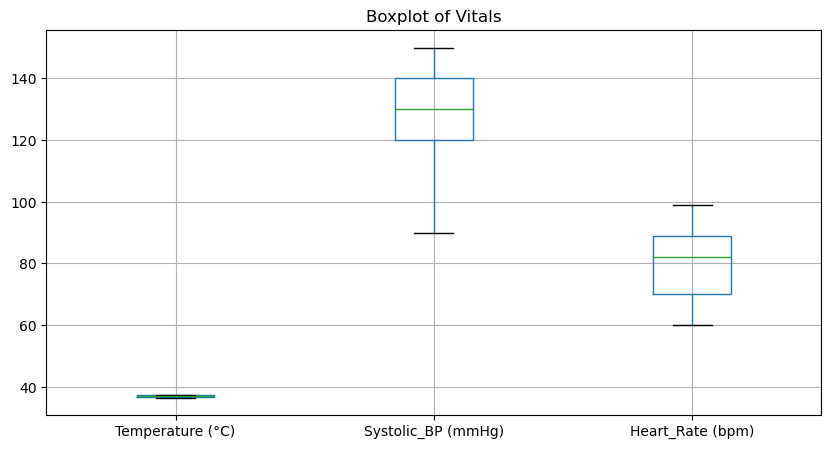

In [7]:
plt.figure(figsize=(10, 5))
df[['Temperature (°C)', 'Systolic_BP (mmHg)', 'Heart_Rate (bpm)']].boxplot()
plt.title("Boxplot of Vitals")
plt.show()


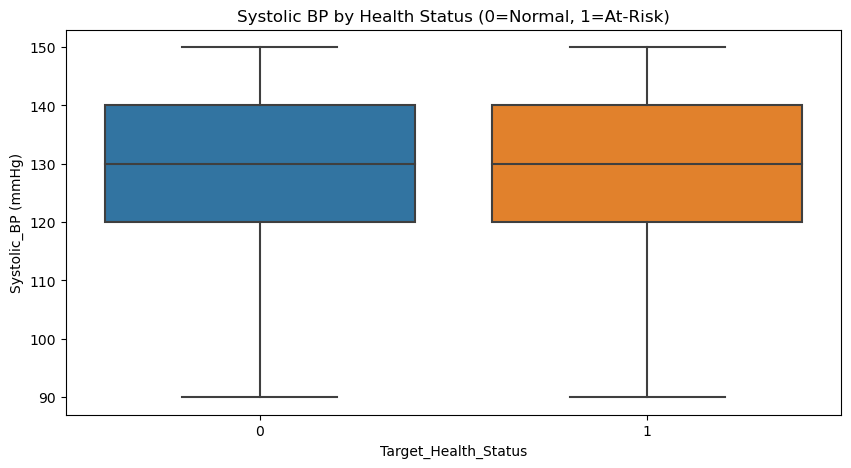

In [8]:
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.boxplot(x='Target_Health_Status', y='Systolic_BP (mmHg)', data=df)
plt.title("Systolic BP by Health Status (0=Normal, 1=At-Risk)")
plt.show()


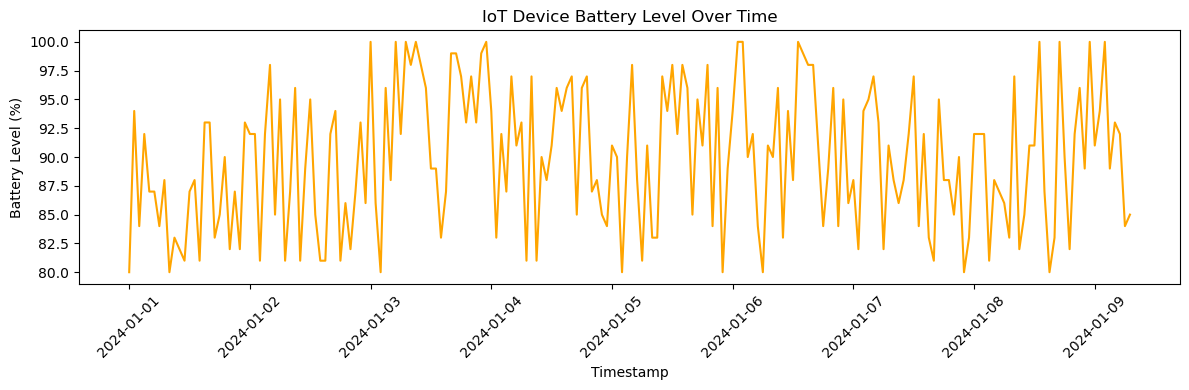

In [9]:
plt.figure(figsize=(12, 4))
plt.plot(df['Timestamp'], df['Battery_Level'], color='orange')
plt.title("IoT Device Battery Level Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Battery Level (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


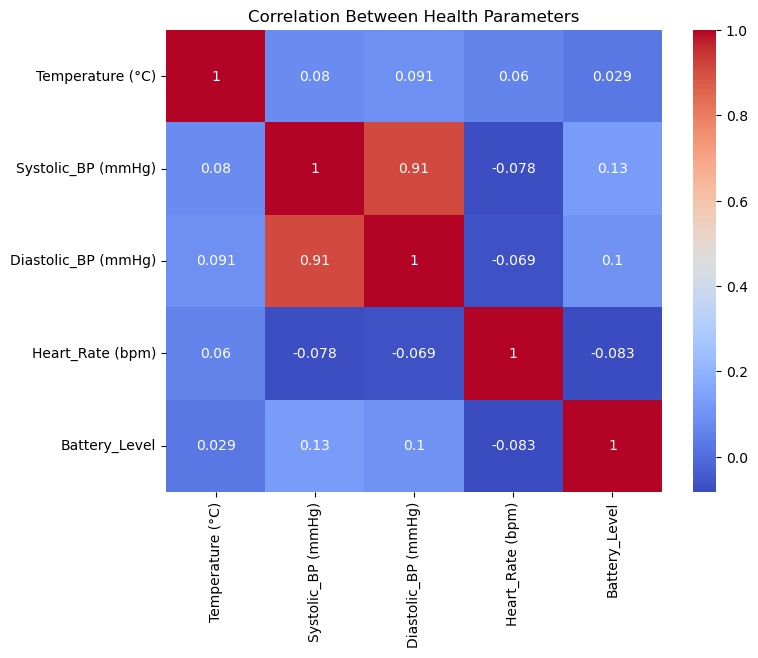

In [10]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[['Temperature (°C)', 'Systolic_BP (mmHg)', 'Diastolic_BP (mmHg)', 
                'Heart_Rate (bpm)', 'Battery_Level']].corr(), 
            annot=True, cmap='coolwarm')
plt.title("Correlation Between Health Parameters")
plt.show()


In [11]:
vital_columns = [
    "Temperature (°C)",
    "Systolic_BP (mmHg)",
    "Diastolic_BP (mmHg)",
    "Heart_Rate (bpm)"
]

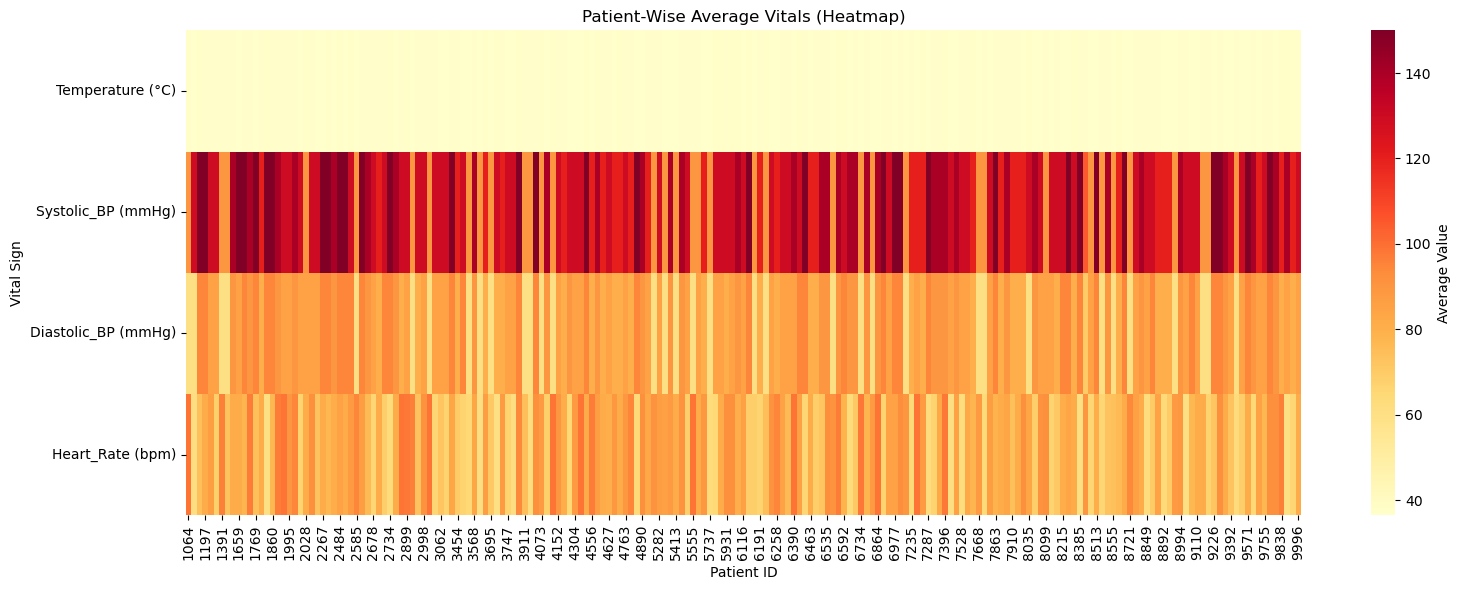

In [12]:
pivot_df = df.groupby("Patient_ID")[vital_columns].mean()
plt.figure(figsize=(16, 6))
sns.heatmap(pivot_df.T, cmap="YlOrRd", cbar_kws={'label': 'Average Value'})
plt.title("Patient-Wise Average Vitals (Heatmap)")
plt.xlabel("Patient ID")
plt.ylabel("Vital Sign")
plt.tight_layout()
plt.show()